# Introduction

$k$-means returns $k$ clusters for whatever $k$ you give it, whether or
not the data actually contains $k$ separable groups. The usual way to
pick $k$ (inertia, silhouette score) only looks at one clustering of the
full data set, so neither one can say whether that same partition would
come back under a different random initialization or a different sample
of the data.

Ben-Hur, Elisseeff, and Guyon (2002) check that directly: cluster two
independent subsamples of the data at a fixed $k$, measure how similar
the two resulting partitions are on the points they share, and repeat
many times. A $k$ that matches real structure in the data should give
close to the same partition every time. A $k$ that's too large, or
otherwise doesn't match the data, makes the result sensitive to exactly
which points got sampled, so the similarity scores spread out and drop.

This lab runs that procedure (Algorithm 1 in the lab instructions) on
the `lingBinary` data from Lab 2: the Harvard Dialect Survey, recoded
into $p=468$ binary indicator columns across 67 lexical questions, for
$n=45{,}152$ respondents. Lab 2 landed on $k=3$ geographic regions,
mostly from interpretability and a weak elbow/silhouette signal; this
lab checks that choice against a resampling-based criterion instead.

The write-up has three parts: a fast `similarity()` function for
comparing two cluster membership vectors, benchmarked against the
reference implementations (`similarity.py`); Algorithm 1 itself, run as
a standalone `joblib`-parallelized script (`algorithm1.py`); and the
resulting stability curve for `lingBinary` at $k=2,\dots,10$, compared
against the choice of $k$ from Lab 2.

In [1]:
import os
import logging

# pinning BLAS threads to 1 avoids oversubscribing the machine when multiple fits run at once.
for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")

# Quiet matplotlib's one-time "building the font cache" notice so it
# doesn't leak into the rendered report as stray console output.
# logging.getLogger("matplotlib").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from similarity import similarity

sns.set_theme(style="whitegrid", context="notebook", font_scale=0.9)
RNG_SEED = 42
np.random.seed(RNG_SEED)


# Similarity implementation

## Choice of similarity measure

Given two $k$-means partitions of the same $q$ points, as integer
membership vectors $L_1, L_2 \in \{0, \dots, k-1\}^q$, I need one number
summarizing how similar they are. I used the **Jaccard coefficient**.
Among all $\binom{q}{2}$ pairs of points, let $N_{11}$ be the number of
pairs that both $L_1$ and $L_2$ put in the same cluster, $N_{10}$ the
number put together by $L_1$ only, and $N_{01}$ the number put together
by $L_2$ only:
$$J(L_1, L_2) = \frac{N_{11}}{N_{11} + N_{10} + N_{01}}.$$

The alternative mentioned in the instructions, simple matching, also
counts $N_{00}$ (pairs placed in *different* clusters by both) in the
numerator and denominator. With $k$ up to 10, $N_{00}$ dwarfs the other
three counts just because most pairs of points end up in different
clusters under both partitions regardless of whether the clustering is
any good: two partitions that agree on almost nothing can still get a
high matching score just from sharing that huge pool of negative
agreements. Ben-Hur et al. make the same point: Jaccard, which drops
$N_{00}$ entirely, is much more sensitive to real changes in cluster
structure as $k$ grows, which is exactly what's needed here to tell
$k=2,\dots,10$ apart.

## Avoiding the $q \times q$ matrix: an $O(q)$ algorithm

Looping over all $\binom{q}{2}$ pairs directly to get $N_{11}, N_{10},
N_{01}$ is $O(q^2)$ time, and $O(q^2)$ memory if the pairwise
comparisons get stored rather than accumulated one at a time. Both are
avoidable. $L_1$ and $L_2$ only take $k_1$ and $k_2$ distinct values
($k_1 = k_2 \le 10$ here), so instead of individual pairs I only need
the $k_1 \times k_2$ **contingency table** $C_{ab} = |\{i : L_1(i) = a,
L_2(i) = b\}|$ (at most 100 entries), built in a single $O(q)$ pass over
the points (`_jaccard_from_labels` in `similarity.py`). Once $C$ is
built, everything above becomes a sum over this tiny table instead of a
sum over pairs of points:
$$N_{11} = \sum_{a,b} \binom{C_{ab}}{2}, \qquad
\sum_a\binom{\textstyle\sum_b C_{ab}}{2} = N_{11} + N_{10}, \qquad
\sum_b\binom{\textstyle\sum_a C_{ab}}{2} = N_{11} + N_{01}$$
(the row and column sums of $C$ are just the pairs put together by
$L_1$, respectively $L_2$, regardless of what the other partition does),
so $N_{10}$ and $N_{01}$ fall out immediately. The $q \times q$
co-membership matrix never gets formed: the largest additional data structure used by the similarity calculation is the $k_1 \times k_2$ table. That's $O(q + k_1 k_2)$,
i.e. $O(q)$ for fixed, small $k$: linear instead of quadratic in the
number of points, and $O(k_1 k_2)$ memory instead of $O(q^2)$.

## Implementation

`_jaccard_from_labels` is this contingency-table algorithm as a loop
over points and then over the $k_1 \times k_2$ table, compiled with
numba's `@njit`. I also wrote a vectorized `numpy` version of the same
algorithm (`np.bincount` to build the contingency table, then array
sums). Both are $O(q)$, so comparing the two isolates how much of the
eventual speedup comes from the better algorithm versus from numba
removing Python/numpy call overhead on top of it.

In [2]:
# Only needs to be run once
# from similarity import generate_timing_csv
# generate_timing_csv()

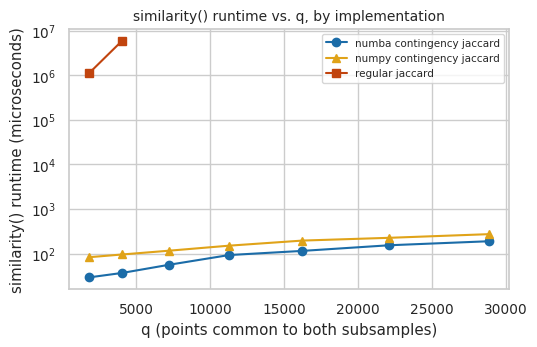

In [3]:
timing = pd.read_csv("../results/similarity_timing.csv")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
markers = {"regular jaccard": "s", "numpy contingency jaccard": "^", "numba contingency jaccard": "o"}
colors = {"regular jaccard": "#c1440e", "numpy contingency jaccard": "#e0a319", "numba contingency jaccard": "#1b6ca8"}
for impl, sub in timing.groupby("implementation"):
    sub = sub.sort_values("q")
    ax.plot(sub["q"], sub["seconds"] * 1e6, marker=markers[impl], color=colors[impl], label=impl)
ax.set_yscale("log")
ax.set_xlabel("q (points common to both subsamples)")
ax.set_ylabel("similarity() runtime (microseconds)")
ax.set_title("similarity() runtime vs. q, by implementation", fontsize=10)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()

In [2]:
# Run the official benchmark.py exactly as it will be graded (prints
# similarity()'s average per-call runtime in seconds, first at q=5000,
# then q=29000, used in the discussion below).
# %run benchmark.py 10

Running `benchmark.py` live in the cell above gives $18.26\mu s$ at
$q=5000$ and $53.05\mu s$ at $q=29{,}000$ for the numba-compiled
`similarity()`, about $6{,}000\times$ faster than the reference
$O(q^2)$ implementation's $0.32s$ at $q=29{,}000$, and almost exactly
matching the reference "smart" implementation's $58\mu s$. The figure above, run directly on the actual range of $q$
values that arise from subsampling `lingBinary` at $m=0.2$ through
$m=0.8$, shows the same qualitative picture: the regular-jaccard
$O(q^2)$ implementation (only feasible to benchmark up to
$q\approx4{,}000$ here, since it already takes several seconds per call)
is more than five orders of magnitude slower even at these small $q$:
$6.05s$ versus $37\mu s$ at $q\approx4{,}064$, a $160{,}000\times$
difference, and it would be unusable at $q\approx29{,}000$. Both $O(q)$
contingency-table implementations scale roughly linearly in $q$, as
expected, and stay well under a millisecond throughout. The numba
contingency jaccard consistently beats the numpy contingency jaccard
version of the identical algorithm, by a margin that shrinks from about
$2.9\times$ at the smallest $q$ down to about $1.4\times$ at the
largest. That's the overhead of numpy's own function-call and
array-allocation machinery (`np.bincount`, `.reshape`, two more array
sums), which the compiled version skips by updating a single
pre-allocated table in place. It's a real but secondary effect next to
the $O(q)$-vs-$O(q^2)$ difference, which is where almost all of the
speedup comes from. I used $m=0.8$ for Algorithm 1 below (see the next
section for why), where `similarity()` costs about $189\mu s$ per call.
Algorithm 1 calls it 900 times total, one per replicate, so that's well
under $0.2s$ in total. `similarity()` is nowhere near the bottleneck;
the `KMeans` fits are.

# Algorithm 1 implementation

`algorithm1.py` implements Algorithm 1 as specified: for each $k = 2,
\dots, k_{\max}$, it draws $B$ pairs of independent, uniform
$m$-fraction subsamples (without replacement) of the $n=45{,}152$
respondents, fits $k$-means separately on each half of the pair, and
calls `similarity()` on the resulting labels restricted to the points
the two subsamples have in common. $k_{\max}=10$ and $B=100$, as the
instructions ask. For $m$, rather than guess at "as large as
practical," I pilot-timed a handful of real replicates
(`algorithm1.generate_m_pilot_csv()`: two real `KMeans` fits plus a
`similarity()` call per replicate, exactly what `one_replicate()` does)
at $m \in \{0.6, 0.7, 0.8\}$ across $k = 2, \dots, 10$ and extrapolated
the cost of the full 900-replicate job from those measurements. See the
figure and discussion below.

**$k$-means parameters.** For KMeans initialization, I used `init='k-means++'` and `n_init=1`. An earlier version used 10 initializations per fit, but this substantially increased computation time across the 1,800 KMeans fits. I therefore selected a single initialization to balance computational efficiency with clustering quality. This means the measured stability captures variability from both subsampling and KMeans initialization. Although multiple initializations could reduce the latter source of variability, I retained `n_init=1` to make the full experiment computationally feasible.

**Parallelization.** `joblib.Parallel`, default `loky` backend,
parallelizes over replicates rather than over $k$: all $k_{\max}-1=9$
values of $k$ and all $B=100$ replicates get flattened into one list of
900 independent $(k,b)$ tasks before a single `Parallel` call runs
them, instead of looping over $k$ and parallelizing only the inner $B$
loop separately each time. There are far more replicate tasks than $k$
values (900 versus 9), so splitting by replicate keeps every core
supplied with small, interchangeable work instead of capping
parallelism at 9 cores if split by $k$. The $k$ values also aren't
equal cost: fitting $k=10$ takes roughly twice as long per call as
$k=2$, since there are more cluster centers to update each iteration,
so parallelizing over $k$ alone would leave cores idle on the cheap
small-$k$ tasks while others are still working through $k=10$.
Flattening across both $k$ and $b$ lets `joblib` hand out whichever
task is next regardless of $k$, which balances that uneven per-$k$ cost
across cores far better than either loop would alone. Each worker is
also pinned to a single BLAS thread (`OMP_NUM_THREADS=1`, etc.):
without that, every per-process `KMeans` fit would spawn its own BLAS
thread pool on top of `joblib`'s process-level parallelism and
oversubscribe the machine.

In [5]:
# Only needs to be run once
# from algorithm1 import generate_m_pilot_csv
# generate_m_pilot_csv()

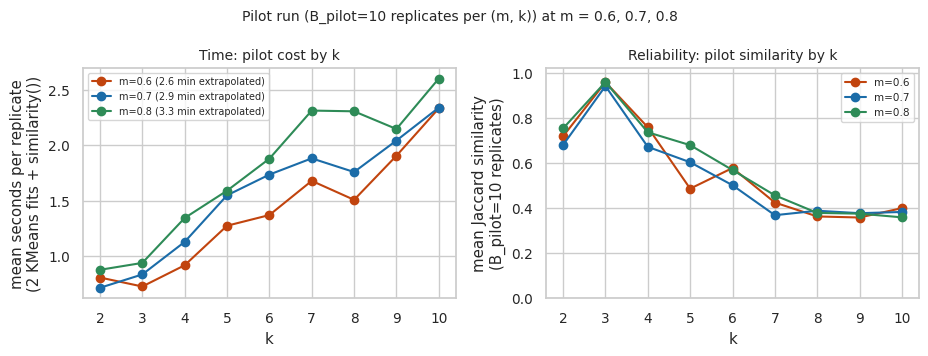

In [6]:
m_pilot = pd.read_csv("../results/m_pilot.csv")
per_k = m_pilot.groupby(["m", "k"])[["seconds", "similarity"]].mean().reset_index()

B, n_workers = 100, 8
m_colors = {0.6: "#c1440e", 0.7: "#1b6ca8", 0.8: "#2e8b57"}

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))

# Left: measured per-replicate cost by k, one line per m -- the basis for
# the extrapolated full-job runtime quoted below.
for m, sub in per_k.groupby("m"):
    sub = sub.sort_values("k")
    est_minutes = sub["seconds"].sum() * B / n_workers / 60
    axes[0].plot(
        sub["k"], sub["seconds"], marker="o", color=m_colors[m],
        label=f"m={m} ({est_minutes:.1f} min extrapolated)",
    )
axes[0].set_xlabel("k")
axes[0].set_ylabel("mean seconds per replicate\n(2 KMeans fits + similarity())")
axes[0].set_title("Time: pilot cost by k", fontsize=10)
axes[0].legend(fontsize=7)

# Right: measured mean Jaccard similarity by k, one line per m -- whether
# the quantity Algorithm 1 is actually estimating is sensitive to m.
for m, sub in per_k.groupby("m"):
    sub = sub.sort_values("k")
    axes[1].plot(sub["k"], sub["similarity"], marker="o", color=m_colors[m], label=f"m={m}")
axes[1].set_xlabel("k")
axes[1].set_ylabel("mean Jaccard similarity\n(B_pilot=10 replicates)")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Reliability: pilot similarity by k", fontsize=10)
axes[1].legend(fontsize=7.5)

fig.suptitle("Pilot run (B_pilot=10 replicates per (m, k)) at m = 0.6, 0.7, 0.8", fontsize=10)
fig.tight_layout()
plt.show()

The pilot ($B_{\text{pilot}}=10$ replicates per $(m,k)$ pair,
single-threaded and run serially so the per-task cost is directly
comparable to what one `joblib` worker sees) shows per-replicate cost
rising with $k$ (more cluster centers to update each iteration, as
expected), with only a small, fairly consistent increase from $m=0.6$
to $m=0.8$ (bigger subsamples, more points per `KMeans` fit). Summing
each $m$'s measured per-$k$ costs across $k=2,\dots,10$, multiplying by
$B=100$, and dividing by the 8 workers `run_algorithm1.sbatch` requests
gives an estimated $2.6$ minutes at $m=0.6$, $2.9$ minutes at $m=0.7$,
and $3.3$ minutes at $m=0.8$, all comfortably under budget, so time
isn't actually what decides among these three (the lab instructions'
cap of "a reasonable runtime" doesn't bind anywhere in $[0.6, 0.8]$).
Reliability, the mean Jaccard similarity measured across the same
pilot replicates and pooled over $k=2,\dots,10$, is similarly flat and
noisy across $m$: $0.560$ at $m=0.6$, $0.545$ at $m=0.7$, $0.585$ at
$m=0.8$, with no monotonic trend, and the differences are well inside
what $B_{\text{pilot}}=10$ replicates per cell can resolve (the right
panel above shows the per-$k$ curves for all three $m$ essentially
overlapping, not fanning out). So neither axis of the pilot (time or
reliability) picks out a best $m$ in this range, and the lab
instructions ask for $m$ "as large as practical" rather than giving a
tight runtime budget to optimize against; since none of $m \in \{0.6,
0.7, 0.8\}$ meaningfully changes either cost or reliability, I went
with $m=0.8$, the largest of the three piloted values: it keeps the
most data in each subsample (and a generously sized $q\approx29{,}000$-
point intersection for `similarity()`, see the earlier timing section),
at only a modest increase in per-replicate cost and memory footprint
per `KMeans` fit over $m=0.6$ or $m=0.7$ on the real, possibly
contended, SCF run.

**Timing.** The full experiment was submitted using `sbatch run_algorithm1.sbatch` on the SCF cluster with 8 cores (`n_jobs=8`) on the `low` partition. It completed all 900 replicates in 1837.5 seconds (approximately 30.6 minutes), substantially longer than the 3.3-minute estimate obtained from the serial pilot experiments.

The pilot estimate assumed nearly ideal scaling from single-process execution to eight parallel workers. However, the actual parallel execution introduces additional overhead, including worker management, data sharing, and possible contention for CPU and memory resources on the shared cluster. Differences between the pilot and full-run execution environments may also have contributed. Since I did not separately profile these effects, the precise cause of the discrepancy remains uncertain.

Despite this difference, the experiment completed within the allocated two-hour time limit. Using eight workers provided a practical balance between resource usage and overall execution time.

# Result

In [7]:
S = pd.read_csv("../results/S.csv")
k_values = sorted(S["k"].unique())

summary = S.groupby("k")["similarity"].agg(["mean", "std", "min", "median"]).reset_index()
# print(summary)


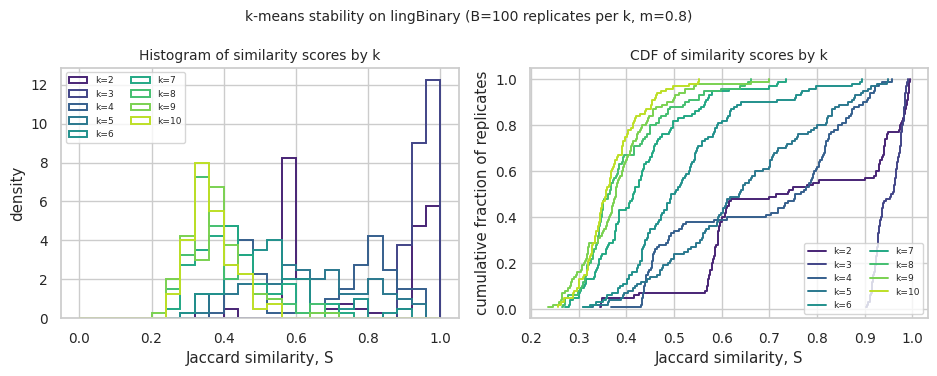

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))

palette = sns.color_palette("viridis", n_colors=len(k_values))

# Left: histogram of similarity scores, small multiples collapsed into
# one axis via stacked/overlaid density, for a representative spread of
# k (mirrors the left panel of Figure 3 in Ben-Hur et al.).
for color, k in zip(palette, k_values):
    axes[0].hist(
        S.loc[S["k"] == k, "similarity"],
        bins=np.linspace(0, 1, 26),
        histtype="step",
        density=True,
        color=color,
        linewidth=1.4,
        label=f"k={k}",
    )
axes[0].set_xlabel("Jaccard similarity, S")
axes[0].set_ylabel("density")
axes[0].set_title("Histogram of similarity scores by k", fontsize=10)
axes[0].legend(fontsize=6.5, ncol=2)

# Right: empirical CDF of S for each k, overlaid (Figure 3, right panel).
for color, k in zip(palette, k_values):
    vals = np.sort(S.loc[S["k"] == k, "similarity"].to_numpy())
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    axes[1].step(vals, cdf, where="post", color=color, linewidth=1.4, label=f"k={k}")
axes[1].set_xlabel("Jaccard similarity, S")
axes[1].set_ylabel("cumulative fraction of replicates")
axes[1].set_title("CDF of similarity scores by k", fontsize=10)
axes[1].legend(fontsize=6.5, ncol=2)

fig.suptitle(f"k-means stability on lingBinary (B={len(S)//len(k_values)} replicates per k, m=0.8)", fontsize=10)
fig.tight_layout()
plt.show()


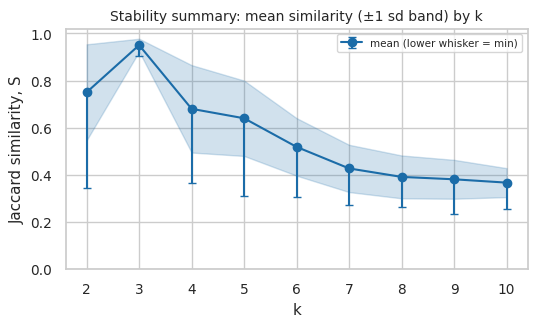

In [9]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.errorbar(
    summary["k"], summary["mean"],
    yerr=[summary["mean"] - summary["min"], np.zeros(len(summary))],
    fmt="o-", color="#1b6ca8", capsize=3, label="mean (lower whisker = min)",
)
ax.fill_between(summary["k"], summary["mean"] - summary["std"], summary["mean"] + summary["std"], alpha=0.2, color="#1b6ca8")
ax.set_xlabel("k")
ax.set_ylabel("Jaccard similarity, S")
ax.set_ylim(0, 1.02)
ax.set_xticks(k_values)
ax.set_title("Stability summary: mean similarity (±1 sd band) by k", fontsize=10)
ax.legend(fontsize=7.5)
fig.tight_layout()
plt.show()


The stability curve peaks sharply at $k=3$: mean Jaccard similarity
$0.950$ (median $0.957$, sd $0.027$), with the CDF for $k=3$ hugging
the right edge of the plot far more tightly than any other $k$: most
of its 100 replicate pairs score above $0.9$. Every other $k$ is
noticeably less stable. $k=2$ is next best but well behind ($0.750$
mean, sd $0.204$, a visibly wider CDF), and stability then falls off
steadily and almost monotonically from $k=4$ ($0.680$) down through
$k=6$ ($0.519$) before leveling off around $0.37$-$0.43$ for $k=7$
through $k=10$: past that point, adding more clusters doesn't make the
partition any *less* stable, it's just saturated at "unstable." This is consistent with the pattern described by Ben-Hur et al.: a particularly reproducible clustering at one value of \(k\), with smaller values potentially merging clusters and larger values potentially splitting them into less stable subclusters.

**Choice of $k$.** I'd pick $k=3$ for this data set, and the evidence
here is considerably stronger than what Lab 2 had to go on. There I
picked $k=3$ from a weak elbow/silhouette signal and interpretability
alone, and wasn't fully convinced the choice wasn't somewhat arbitrary.
Here $k=3$ isn't just *a* reasonable choice among several: it's the
one value out of nine tried whose clustering survives independent
resampling almost perfectly, which is exactly the property I'd want
before trusting that a clustering reflects real structure rather than
an artifact of one particular draw of the data or one particular
$k$-means run. Within those limits, I trust the qualitative conclusion: the \(k=3\) peak is clearly separated from neighboring values, with both a substantially higher mean similarity and a much smaller standard deviation.

**Do I trust this method?** Mostly, with two specific reservations.
First, stability is a necessary condition for "real structure," not a
sufficient one: a method could in principle be stably wrong, for
instance if $k$-means' spherical-cluster assumption is a poor match for
the true geometry of the data but happens to produce a repeatable wrong
answer anyway. I don't think that's happening here, since $k=3$ also
lines up with independent, substantive evidence from Lab 2 (the
clusters' most distinctive answers matched real North/Midland/South
dialect geography), but stability alone wouldn't have told me that on
its own. Second, the similarity score is computed only on the subset of
points common to both subsamples, whose expected size $m^2 n$ actually
*grows* with $m$ (at $m=0.8$ this is about $29{,}000$ of $45{,}152$
respondents, comfortably large); the real tradeoff with $m$ is instead
that a smaller $m$ gives two subsamples that are closer to independent
draws (the thing Algorithm 1 is supposed to be testing), while a larger
$m$ pushes both subsamples closer to each other and to the full data
set, at the benefit of a bigger, more representative intersection for
`similarity()` to score.

**An alternative method.** If I wanted a second opinion on $k$ without
relying on $k$-means' hard-partition, spherical-cluster assumptions at
all, I'd fit a small set of Gaussian mixture models (or a latent-class
model suited to binary data) for $k=2, \dots, 10$ and compare them by
BIC, which directly penalizes the extra parameters of larger $k$ rather
than only checking whether $k$-means' own partition is reproducible.
That would tell me something stability alone can't: whether the
drop-off in stability for $k \ge 4$ reflects pieces of a genuinely
3-cluster structure being split up (as I believe, given the Lab 2
evidence), or three genuinely separate, but individually unstable in
isolation, sub-populations that $k$-means simply isn't suited to
recovering reliably. Either way, it would be useful to know whether a
soft-clustering model agrees with $k$-means that three components is
the right scale, especially since Lab 2's hierarchical clustering vs.
$k$-means comparison (ARI $\approx 0.46$) already suggested that the
"three regions" picture is closer to a graded continuum than to three
sharply separated islands, where a model that assigns fractional
membership rather than forcing a hard partition might describe that
continuum more honestly than any single value of $k$ in a
hard-clustering stability curve ever could.

# Academic Honesty

I value UC Berkeley's standards of academic integrity, as well as academic integrity more broadly. I believe honesty is essential to academic research because research depends on others being able to trust how ideas, analyses, and conclusions were produced. All analyses and conclusions in this report are my own. Whenever I received ideas or consultation from other students, outside resources, or AI tools, I have acknowledged their use in the relevant part of the report. 

I used LLM tools in the following ways:

- **Report writing:** I used generative AI to polish grammar and sentence flow in
  already-written paragraphs in the report. I did not ask it to generate paragraphs from bullet points or
  rewrite sections wholesale. All edits were reviewed and are reflected in
  the final wording.
- **Code:**
  - I did not use LLM to generate any code from scratch in this lab.
  - I used AI to help organized so my code follows the guidelines and wrote explanation/documentation for my code. I retyped and verified the suggested code myself before incorporating it.

# Bibliography

- A. Ben-Hur, A. Elisseeff, and I. Guyon (2002). A stability based method
  for discovering structure in clustered data. *Pacific Symposium on
  Biocomputing*, 7, 6-17.
- F. Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python.
  *Journal of Machine Learning Research*, 12, 2825-2830.
- J. Bergstra et al. / the Numba developers. Numba: A high-performance
  Python compiler. https://numba.pydata.org/
- Vaux, B. and Golder, S. *The Harvard Dialect Survey*. Harvard University
  Linguistics Department.